# IFRS 9 expected credit loss with Markov chains and macro scenarios

**Objective:** calculate the expected credit loss (ECL) of a credit card portfolio like the IFRS 9 standard asks: classify the clients in stages, estimate 12-month and lifetime PD, and make the PD forward-looking with macroeconomic scenarios.

- **PD:** a Markov chain of the monthly delinquency states, estimated with the payment history of each client. Lifetime PD comes from the powers of the transition matrix.
- **Forward-looking:** a satellite model that links the charge-off rate of US credit cards with unemployment (FRED), and three scenarios (base, adverse, upside) weighted by probability.
- **LGD and EAD:** assumptions documented in Part 6.

**Data:** "Default of credit card clients" (UCI, 30.000 clients with 6 months of payment status, April to September 2005) and FRED (UNRATE, CORCCACBS).

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `requests` and `statsmodels`.

## Part 1. Libraries and data

In [1]:
import io
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import statsmodels.api as sm

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

ruta = "data/default_credit_card_clients.xls"
if not os.path.exists(ruta):
    z = zipfile.ZipFile(io.BytesIO(requests.get("https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip", timeout=120).content))
    with open(ruta, "wb") as f:
        f.write(z.read([n for n in z.namelist() if n.endswith(".xls")][0]))
df = pd.read_excel(ruta, header=1).rename(columns={"PAY_0": "PAY_1", "default payment next month": "default"})
print("Clients:", len(df))

Clients: 30000


## Part 2. Delinquency states

The variables PAY_6 (April) to PAY_1 (September) are the payment status of each month: -2 and -1 paid, 0 revolving but up to date, 1 = one month late, 2 = two months late, and so on.

First we look at the codes of each month:

In [2]:
meses = ["PAY_6", "PAY_5", "PAY_4", "PAY_3", "PAY_2", "PAY_1"]    # from April to September
pd.DataFrame({m: df[m].clip(-2, 4).value_counts().sort_index() for m in meses}).fillna(0).astype(int)

,PAY_6,PAY_5,PAY_4,PAY_3,PAY_2,PAY_1
-2,4895,4546,4348,4085,3782,2759
-1,5740,5539,5687,5938,6050,5686
0,16286,16947,16455,15764,15730,14737
1,0,0,2,4,28,3688
2,2766,2626,3159,3819,3927,2667
3,184,178,180,240,326,322
4,129,164,169,150,157,141


Problem in the data: the code 1 (one month late) almost only appears in September (PAY_1). In the other months the clients jump from 0 to 2. It is a known issue of this dataset, so a state "1 month late" would be estimated with almost no transitions. We use 3 states:

- **C**: current (0 or less)
- **D**: 1 or 2 months late
- **DF**: 3 or more months late = default (absorbing state, as in the 90 days past due definition)

In [3]:
def estado(x):
    if x <= 0:
        return "C"
    if x <= 2:
        return "D"
    return "DF"

estados = ["C", "D", "DF"]
st = df[meses].map(estado)
st.apply(pd.Series.value_counts).reindex(estados).fillna(0).astype(int)

,PAY_6,PAY_5,PAY_4,PAY_3,PAY_2,PAY_1
C,26921,27032,26490,25787,25562,23182
D,2766,2626,3161,3823,3955,6355
DF,313,342,349,390,483,463


## Part 3. Transition matrix

We count all the transitions from one month to the next (5 transitions for each of the 30.000 clients) and divide by the row totals. Default is absorbing: once in DF the client stays there.

In [4]:
conteo = pd.DataFrame(0, index=estados, columns=estados)
for a, b in zip(meses[:-1], meses[1:]):
    conteo += pd.crosstab(st[a], st[b]).reindex(index=estados, columns=estados).fillna(0)
P = conteo.div(conteo.sum(axis=1), axis=0)
P.loc["DF"] = [0, 0, 1]
print("Transitions counted:", int(conteo.values.sum()))
P.round(4)

Transitions counted: 150000


,C,D,DF
C,0.9388,0.0612,0.0000
D,0.2529,0.6840,0.0631
DF,0.0000,0.0000,1.0000


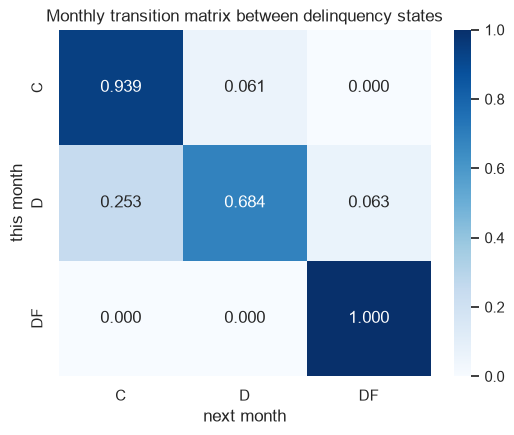

In [5]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(P, annot=True, fmt=".3f", cmap="Blues")
plt.title("Monthly transition matrix between delinquency states")
plt.xlabel("next month")
plt.ylabel("this month")
plt.savefig("figures/transition_matrix.png", bbox_inches="tight")
plt.show()

## Part 4. 12-month and lifetime PD

The probability of being in default after n months is the DF column of P^n. Lifetime PD for a credit card has no contractual maturity, so we use a behavioural life of 36 months (an assumption that has to be documented).

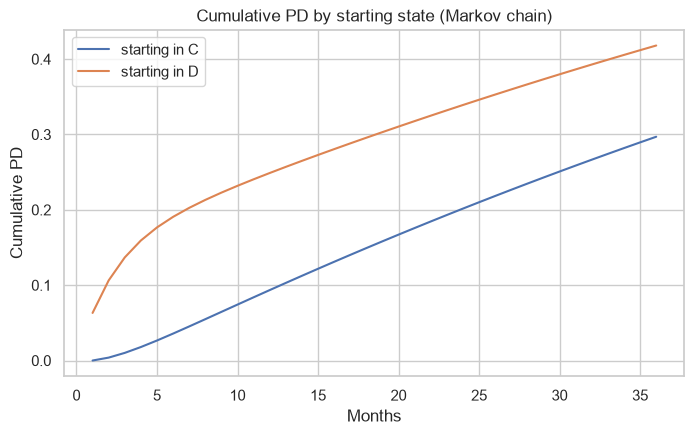

,PD 12 months,PD lifetime (36 months)
C,0.0935,0.2969
D,0.2488,0.4180
DF,1.0000,1.0000


In [6]:
def pd_acumulada(P, n):
    return np.linalg.matrix_power(P.values, n)[:, -1]

horizonte = np.arange(1, 37)
curvas = pd.DataFrame([pd_acumulada(P, n) for n in horizonte], index=horizonte, columns=estados)
plt.figure(figsize=(8, 4.5))
for e in ["C", "D"]:
    plt.plot(curvas.index, curvas[e], label="starting in " + e)
plt.title("Cumulative PD by starting state (Markov chain)")
plt.xlabel("Months")
plt.ylabel("Cumulative PD")
plt.legend()
plt.savefig("figures/pd_term_structure.png", bbox_inches="tight")
plt.show()
pd.DataFrame({"PD 12 months": curvas.loc[12], "PD lifetime (36 months)": curvas.loc[36]}).round(4)

## Part 5. Forward-looking: satellite model with unemployment

The matrix was estimated in a specific moment. To move the PD with the economy, we estimate how the charge-off rate of US credit cards reacts to unemployment.

In levels the relation is very weak (the level of charge-offs changed a lot between decades), so we use annual changes:

change in 4 quarters of logit(charge-off rate) = a + b x change in 4 quarters of unemployment

We leave out 2020Q1-2022Q2: unemployment jumped with COVID but charge-offs fell, because of the stimulus checks and payment holidays. That period would break the relation.

In [7]:
def fred(s):
    d = pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={s}", index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
    return d.astype(float).dropna()

co = fred("CORCCACBS") / 100                         # quarterly charge-off rate on credit card loans
un = fred("UNRATE").resample("QS").mean()            # quarterly average unemployment
lc = np.log(co / (1 - co))
m = pd.DataFrame({"d_logit_co": lc.diff(4), "d_un": un.diff(4)}).dropna()
m = m[~((m.index >= "2020-01-01") & (m.index < "2022-07-01"))]
sat = sm.OLS(m["d_logit_co"], sm.add_constant(m["d_un"])).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(sat.summary().tables[1])
print("R2:", round(sat.rsquared, 3), "| last unemployment:", un.dropna().index[-1].date(), round(un.dropna().iloc[-1], 2))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0491      0.030      1.629      0.103      -0.010       0.108
d_un           0.1723      0.020      8.655      0.000       0.133       0.211
R2: 0.355 | last unemployment: 2026-07-01 4.13


Each point of unemployment increases the log-odds of the charge-off rate by b. For each scenario the multiplier of the odds of default is exp(b x change in unemployment), and we apply it to the PD on the odds scale (so the PD stays below 1).

In [8]:
hoy = un.dropna().iloc[-1]
escenarios = pd.DataFrame({"unemployment": [hoy, hoy + 2.5, hoy - 0.5], "weight": [0.6, 0.3, 0.1]},
                          index=["base", "adverse", "upside"])
escenarios["odds_multiplier"] = np.exp(sat.params["d_un"] * (escenarios["unemployment"] - hoy))
escenarios.round(3)

,unemployment,weight,odds_multiplier
base,4.133,0.6,1.000
adverse,6.633,0.3,1.539
upside,3.633,0.1,0.917


## Part 6. Stages, EAD and LGD

- **Stage 1:** current (C). ECL = 12-month PD
- **Stage 2:** significant increase of credit risk: 1 or 2 months late (D). ECL = lifetime PD
- **Stage 3:** default (DF). PD = 100%
- **EAD:** balance + 50% of the unused limit (credit conversion factor 50%)
- **LGD:** 80% (unsecured credit cards)

In [9]:
df["state"] = st["PAY_1"]
df["stage"] = df["state"].map({"C": 1, "D": 2, "DF": 3})
saldo = df["BILL_AMT1"].clip(lower=0)
df["ead"] = saldo + 0.5 * (df["LIMIT_BAL"] - saldo).clip(lower=0)
lgd = 0.8

def ajustar(pd_base, mult):
    odds = pd_base / (1 - pd_base) * mult
    return odds / (1 + odds)

filas = []
for nombre, esc in escenarios.iterrows():
    pd12 = ajustar(curvas.loc[12, df["state"]].values.clip(1e-6, 1 - 1e-6), esc["odds_multiplier"])
    pdlt = ajustar(curvas.loc[36, df["state"]].values.clip(1e-6, 1 - 1e-6), esc["odds_multiplier"])
    pd_ifrs = np.where(df["stage"] == 1, pd12, np.where(df["stage"] == 2, pdlt, 1.0))
    ecl = pd_ifrs * lgd * df["ead"].values
    filas.append(pd.Series(ecl, index=df.index, name=nombre))
ecl = pd.concat(filas, axis=1)
df["ecl"] = (ecl * escenarios["weight"]).sum(axis=1)

resumen = df.groupby("stage").agg(clients=("ecl", "size"), ead=("ead", "sum"), ecl=("ecl", "sum"))
resumen["coverage_%"] = resumen["ecl"] / resumen["ead"] * 100
resumen.loc["total"] = [resumen["clients"].sum(), resumen["ead"].sum(), resumen["ecl"].sum(), resumen["ecl"].sum() / resumen["ead"].sum() * 100]
resumen.round(2)

,clients,ead,ecl,coverage_%
stage,,,,
1,23182.0,2.699138e+09,2.284416e+08,8.46
2,6355.0,5.625960e+08,2.016210e+08,35.84
3,463.0,3.207943e+07,2.566355e+07,80.00
total,30000.0,3.293814e+09,4.557262e+08,13.84


In [10]:
por_esc = (ecl.sum() / 1e6).rename("ECL (million NTD)")
por_esc["probability-weighted"] = df["ecl"].sum() / 1e6
por_esc.round(1)

base                    415.6
adverse                 557.5
upside                  391.0
probability-weighted    455.7
Name: ECL (million NTD), dtype: float64

## Part 7. Back-test of the PD

The dataset also says if the client defaulted the month after September. We compare it with the one-month PD of the chain.

In [11]:
pd1 = curvas.loc[1, df["state"]].values
bt = pd.DataFrame({"state": df["state"], "pd_1m": pd1, "observed": df["default"]}).groupby("state").mean()
bt.round(4)

,pd_1m,observed
state,,
C,0.0000,0.1383
D,0.0631,0.4872
DF,1.0000,0.7192


The "default next month" of the dataset is not the same definition as our state DF (3 months late): it is any missed payment. That is why the observed rate is much higher than our one-month PD for current clients. This is a typical finding: **the definition of default has to be the same in the model and in the data used to test it.**

## Conclusions

- The Markov chain gives a full term structure of PD from 6 months of history. A current client has a 12-month PD of 9.4% and a lifetime (36 months) PD of 29.7%; a client 1-2 months late has 24.9% and 41.8%.
- With the stages, the coverage (ECL / EAD) is 8.5% in stage 1, 35.8% in stage 2 and 80% in stage 3, 13.8% for the whole portfolio. Moving clients from stage 1 to stage 2 changes the provision a lot, which is why the definition of "significant increase of credit risk" is so important.
- The satellite model links the portfolio to the economy: +1 point of unemployment in a year multiplies the odds of charge-off by around 1.19. In the adverse scenario (+2.5 points) the ECL goes from 416 to 558 million NTD, and the probability-weighted ECL (456) is above the base one, as IFRS 9 expects because losses are not linear in the scenarios.
- The back-test shows a problem of definitions: the "default next month" of the dataset is any missed payment, not 3 months late, so it cannot be used directly to test our PD. The definition of default, the behavioural life, the CCF and the LGD must be documented and validated.